## 1. BUSINESS UNDERSTANDING

### 1.1 Project background

Flooding is a recurring urban risk in Nairobi. Heavy rainfall, terrain characteristics, drainage conditions, land cover and patterns of urban development can contribute to where water accumulates and where flooding may occur.

Flood events can disrupt transport, damage homes and businesses, affect essential services and put lives at risk. Identifying locations that may be more susceptible to flooding can help urban planners, disaster-response teams and other stakeholders prioritise further investigation and risk-reduction activities.

This capstone project uses geographic point data and machine-learning techniques to investigate patterns associated with recorded flood locations in Nairobi and develop a preliminary flood-susceptibility mapping tool.

### 1.2 Problem statement

Nairobi experiences flooding in different locations, but decision-makers need accessible, location-based information to help identify areas that may be more susceptible. Without a consistent way to analyse terrain, land-cover, built-up characteristics and proximity to mapped water features together, it can be difficult to compare locations and prioritise areas for further assessment.

The project therefore seeks to use historical/sample flood labels and geographic characteristics to train and evaluate machine-learning models that estimate the relative flood susceptibility of locations in the study area. The resulting predictions will be presented on a map through an interactive application.

**Important:** The model will estimate susceptibility from the available dataset. It will not provide real-time flood warnings, predict the exact timing or depth of a flood, or guarantee that a location is safe.

## 2. DATA UNDERSTANDING

### 2.1 Dataset Loading


#### 2.1.1 Import Required Libraries

This section imports the Python libraries required for data loading, manipulation, numerical analysis and visualization.

- **Pandas:** Used to load, inspect and manipulate the dataset.
- **NumPy:** Supports numerical operations and data analysis.
- **Matplotlib:** Used to create graphs and visualize patterns in the dataset.
- **Seaborn:** Provides additional statistical visualization capabilities.

These libraries will support the data understanding and preparation stages of the project.


In [1]:
# Import libraries
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)



#### 2.1.2 Load the Flood Susceptibility Dataset

The project dataset is loaded into a Pandas DataFrame named **df**.

The dataset contains geographic sample points, their associated environmental and terrain characteristics, and a binary flood label.

Each row represents a sampled geographic location, while the columns describe its characteristics and recorded flood status.

This dataset will be used to explore relationships between geographic features and flood occurrence before preparing the data for machine learning.


In [2]:
# Load the dataset
df = pd.read_csv("points_features complete.csv")

### 2.2 Initial Dataset Inspection


#### 2.2.1 Dataset Structure and Data Types

The dataset information is examined to understand the structure and data types of each column.

This inspection helps identify:

- The number of non-null values in each column.
- The data type assigned to each variable.
- Columns that may require data type conversion.
- Variables that contain missing observations.

Understanding the data types is important because numerical, categorical and identification variables require different treatment during data preparation and modelling.


In [3]:
df.head()

,point_id,lon,lat,flooded,elevation,slope,local_relief_100,local_relief_500,concavity,land_cover,builtup_100,builtup_500,dist_river,dist_stream,dist_drain,block_id
0,1,37.054329,-1.299028,0,1497.815308,0.643400,0.784040,0.919611,-0.242782,40,0.009070,0.076953,343.582858,343.582858,11410.265778,283_9856
1,2,37.051868,-1.297120,1,1491.494019,1.070903,-0.562037,-3.348700,0.486544,30,0.000000,0.098520,8.770712,8.770712,11157.685323,283_9856
2,3,36.979077,-1.223612,1,1503.143555,0.114747,-0.132010,-1.802306,0.111572,30,0.034014,0.235663,93.445852,93.445852,3906.903944,275_9864
3,4,37.086873,-1.232403,1,1486.456299,0.068787,-0.188992,-0.402524,0.026636,30,0.000000,0.003921,2807.757821,2807.757821,14690.733996,287_9863
4,5,37.068898,-1.188922,0,1480.674805,0.426800,-0.134649,0.193810,0.016965,30,0.000000,0.000000,1369.394675,1369.394675,14274.306088,285_9868


In [4]:
# Rows and Columns
df.shape

(19878, 16)

In [5]:
# Columns names
df.columns.tolist()

['point_id',
 'lon',
 'lat',
 'flooded',
 'elevation',
 'slope',
 'local_relief_100',
 'local_relief_500',
 'concavity',
 'land_cover',
 'builtup_100',
 'builtup_500',
 'dist_river',
 'dist_stream',
 'dist_drain',
 'block_id']

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19878 entries, 0 to 19877
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   point_id          19878 non-null  int64  
 1   lon               19878 non-null  float64
 2   lat               19878 non-null  float64
 3   flooded           19878 non-null  int64  
 4   elevation         19878 non-null  float64
 5   slope             19878 non-null  float64
 6   local_relief_100  19878 non-null  float64
 7   local_relief_500  19878 non-null  float64
 8   concavity         19878 non-null  float64
 9   land_cover        19878 non-null  int64  
 10  builtup_100       19878 non-null  float64
 11  builtup_500       19878 non-null  float64
 12  dist_river        19878 non-null  float64
 13  dist_stream       19878 non-null  float64
 14  dist_drain        19878 non-null  float64
 15  block_id          19878 non-null  object 
dtypes: float64(12), int64(3), object(1)
memo

In [7]:
df.sample(5, random_state=42)


,point_id,lon,lat,flooded,elevation,slope,local_relief_100,local_relief_500,concavity,land_cover,builtup_100,builtup_500,dist_river,dist_stream,dist_drain,block_id
9387,9445,37.071404,-1.241612,1,1488.868164,0.095988,0.269965,0.314444,-0.144754,30,0.000000,0.000000,3856.308633,3856.308633,12870.647622,285_9862
19731,19854,37.061292,-1.199785,1,1475.354858,0.475881,-0.302630,-0.712621,0.139382,30,0.000000,0.000000,667.554773,667.554773,12974.483923,284_9867
18736,18854,36.874847,-1.252687,1,1599.356567,4.281172,-0.972748,-9.502680,0.709131,50,0.870748,0.926870,12.044938,12.044938,1353.515085,263_9861
4420,4446,36.988244,-1.259234,0,1517.871216,1.889360,0.284658,4.481194,-0.127690,50,0.580499,0.533477,1284.605645,1284.605645,3710.964984,276_9860
1692,1699,36.996982,-1.206981,1,1493.609253,0.697952,-0.073805,-0.039736,0.063731,30,0.000000,0.011567,224.816690,224.816690,6609.080561,277_9866



#### 2.2.2 Checking for Duplicate Records

Duplicate records are identified to determine whether identical rows occur more than once in the dataset.

Duplicate observations can introduce unnecessary repetition and may affect the reliability of subsequent analysis and model evaluation.

The result will help determine whether duplicate records need to be removed during data preparation.


In [8]:
df.duplicated().sum()


np.int64(0)


#### 2.2.3 Checking for Missing Values

The total number of missing values across the dataset is calculated.

Missing values are important to identify because incomplete observations can affect statistical analysis and machine-learning algorithms.

This initial check establishes whether missing data is present. A column-level inspection will also be necessary if missing values are identified so that appropriate treatment decisions can be made during data preparation.


In [9]:
df.isna().sum().sum()

np.int64(0)


### 2.3 Initial Data Dictionary

A data dictionary is created to document the meaning and intended project use of each original dataset column.

The dictionary contains three main descriptions:

- **Column name:** Identifies the variable in the dataset.
- **Working description:** Explains what the variable represents.
- **Planned project use:** Describes whether the variable will serve as a predictor, target, metadata or excluded feature.

This documentation helps maintain a clear understanding of the dataset and supports consistent feature selection during the modelling stage.

The data dictionary is also exported as **project_data_dictionary.csv** for reference by other project members.

**Note:** The working descriptions and units should be confirmed against the original dataset documentation where available.


In [12]:
data_dictionary = pd.DataFrame([
    ["point_id", "Unique identifier for a sampled point", "Identifier; not a model predictor"],
    ["lon", "Longitude coordinate", "Retain for mapping; exclude as predictor by default"],
    ["lat", "Latitude coordinate", "Retain for mapping; exclude as predictor by default"],
    ["flooded", "Binary flood label: 1 or 0", "Target variable to predict"],
    ["elevation", "Ground elevation at the point", "Candidate terrain predictor; confirm units"],
    ["slope", "Terrain slope at the point", "Candidate terrain predictor; confirm units"],
    ["local_relief_100", "Local terrain relief over a 100-unit neighbourhood", "Candidate terrain predictor; confirm neighbourhood and units"],
    ["local_relief_500", "Local terrain relief over a 500-unit neighbourhood", "Candidate terrain predictor; confirm neighbourhood and units"],
    ["concavity", "Terrain concavity or landform-shape measure", "Candidate terrain predictor; confirm calculation"],
    ["land_cover", "Land-cover classification code", "Categorical predictor; confirm class legend"],
    ["builtup_100", "Built-up measure within a 100-unit neighbourhood", "Candidate predictor; confirm scale and units"],
    ["builtup_500", "Built-up measure within a 500-unit neighbourhood", "Candidate predictor; confirm scale and units"],
    ["dist_river", "Distance to mapped river feature", "Candidate predictor; confirm units and source"],
    ["dist_stream", "Distance to mapped stream feature", "Candidate predictor; compare with dist_river"],
    ["dist_drain", "Distance to mapped drainage feature", "Excluded according to current project plan"],
    ["block_id", "Identifier for a spatial block", "Retain for spatial splitting; not a model predictor"]
], columns=["column_name", "working_description", "planned_project_use"])

display(data_dictionary)
data_dictionary.to_csv("project_data_dictionary.csv", index=False)
print("project_data_dictionary.csv")


,column_name,working_description,planned_project_use
0,point_id,Unique identifier for a sampled point,Identifier; not a model predictor
1,lon,Longitude coordinate,Retain for mapping; exclude as predictor by default
2,lat,Latitude coordinate,Retain for mapping; exclude as predictor by default
3,flooded,Binary flood label: 1 or 0,Target variable to predict
4,elevation,Ground elevation at the point,Candidate terrain predictor; confirm units
5,slope,Terrain slope at the point,Candidate terrain predictor; confirm units
6,local_relief_100,Local terrain relief over a 100-unit neighbourhood,Candidate terrain predictor; confirm neighbourhood and units
7,local_relief_500,Local terrain relief over a 500-unit neighbourhood,Candidate terrain predictor; confirm neighbourhood and units
8,concavity,Terrain concavity or landform-shape measure,Candidate terrain predictor; confirm calculation
9,land_cover,Land-cover classification code,Categorical predictor; confirm class legend


project_data_dictionary.csv


### 2.4 Exploratory Data Analysis (EDA)

#### 2.4.1 Understanding the Target Variable

The target variable for this project is **flooded**.

This analysis examines the number and percentage of observations belonging to each target class.

It also checks for unexpected values outside the expected binary labels of 0 and 1.

Understanding the target distribution is important because it helps determine whether the dataset contains a balanced representation of flooded and non-flooded locations.

This information will guide later modelling decisions, particularly the choice of evaluation metrics and the handling of potential class imbalance.

In [35]:
print("Target label counts:")
display(df["flooded"].value_counts(dropna=False).sort_index())

print("\nTarget label percentages:")
display((df["flooded"].value_counts(normalize=True, dropna=False) * 100).round(2))

print("\nUnexpected target values:")
display(df.loc[~df["flooded"].isin([0, 1]), "flooded"].value_counts())

Target label counts:


flooded
0    9907
1    9971
Name: count, dtype: int64


Target label percentages:


flooded
1    50.16
0    49.84
Name: proportion, dtype: float64


Unexpected target values:


Series([], Name: count, dtype: int64)

#### 2.4.1.1 Visualising Flood Label Distribution

A bar chart is generated to visually compare the number of observations in the two target classes.

The chart displays:

- Class 0: Locations labelled as not flooded.
- Class 1: Locations labelled as flooded.

Visualising the target distribution makes it easier to identify whether one class is more represented than the other.

This is important because a significant imbalance between the classes may influence model training and evaluation.

The distribution will help inform the selection of appropriate evaluation metrics beyond accuracy alone.


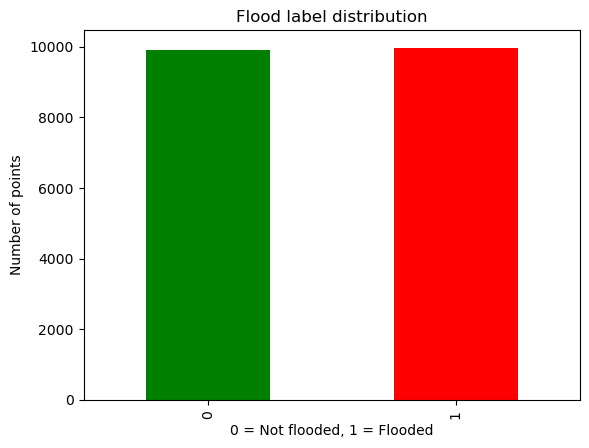

In [36]:
df["flooded"].value_counts().sort_index().plot(kind="bar", color=["green", "red"])
plt.title("Flood label distribution")
plt.xlabel("0 = Not flooded, 1 = Flooded")
plt.ylabel("Number of points")
plt.show()

#### 2.4.2 Descriptive Statistics
Descriptive statistics are generated to summarise the numerical variables in the dataset.

The summary includes:

- **Count:** Number of available observations.
- **Mean:** Average value.
- **Standard deviation:** Measures the spread of values.
- **Minimum:** Lowest recorded value.
- **25%:** First quartile.
- **50%:** Median value.
- **75%:** Third quartile.
- **Maximum:** Highest recorded value.

This analysis helps us understand the distribution, range and variability of the numerical features.

It also helps identify unusually large or small values that may require further investigation before modelling.


In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
point_id,19878.0,9999.263105,5775.130493,1.000000,4999.250000,10000.500000,15000.750000,20000.000000
lon,19878.0,37.005080,0.064685,36.839195,36.958303,37.016174,37.060580,37.099993
lat,19878.0,-1.236748,0.042658,-1.322505,-1.270818,-1.233550,-1.207094,-1.150003
flooded,19878.0,0.501610,0.500010,0.000000,0.000000,1.000000,1.000000,1.000000
elevation,19878.0,1514.027581,48.175153,1442.777466,1483.570923,1493.473511,1531.087830,1671.097168
slope,19878.0,1.455381,2.070879,0.000000,0.359421,0.720067,1.658999,30.989304
local_relief_100,19878.0,-0.196670,1.336403,-19.228974,-0.346517,-0.042193,0.189490,11.901900
local_relief_500,19878.0,-1.156090,4.579180,-32.425903,-1.624908,-0.197344,0.536788,20.215658
concavity,19878.0,0.104250,0.680271,-5.451727,-0.082946,0.018696,0.163896,10.207410
land_cover,19878.0,33.680954,11.270288,10.000000,30.000000,30.000000,40.000000,90.000000


#### 2.4.3 Univariate Analysis

In [29]:
# Univariate Statistical Summary 
# 1. Select numeric features (elevation, slope, concavity, distances)
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop('land_cover', errors='ignore')

# 2. Comprehensive statistical summary with extended percentiles
univ_summary = df[numeric_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T

# 3. Add Skewness to detect heavily right-skewed water distances or elevation tails
univ_summary['skewness'] = df[numeric_cols].skew()

# 4. Calculate outlier percentages using the IQR method
outlier_percentages = {}
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_percentages[col] = (len(outliers) / len(df)) * 100

univ_summary['outlier_pct'] = pd.Series(outlier_percentages)

#  Univariate summary table
display(univ_summary[['mean', 'std', '50%', 'skewness', 'outlier_pct']].rename(columns={'50%': 'median'}))

,mean,std,median,skewness,outlier_pct
point_id,9999.263105,5775.130493,10000.500000,0.000023,0.000000
lon,37.005080,0.064685,37.016174,-0.576523,0.000000
lat,-1.236748,0.042658,-1.233550,-0.096425,0.000000
flooded,0.501610,0.500010,1.000000,-0.006440,0.000000
elevation,1514.027581,48.175153,1493.473511,1.234472,9.518060
slope,1.455381,2.070879,0.720067,3.813358,9.513029
local_relief_100,-0.196670,1.336403,-0.042193,-2.332572,16.727035
local_relief_500,-1.156090,4.579180,-0.197344,-1.831231,19.026059
concavity,0.104250,0.680271,0.018696,2.599753,17.743234
builtup_100,0.204720,0.321463,0.006803,1.412453,10.725425


####  Key Insights: Univariate Statistical Summary

* **Balanced Target (`flooded):** With a mean of **0.502** (50.2% flooded vs. 49.8% non-flooded), the target classes are evenly balanced and require no synthetic oversampling.

* **Heavy Skewness & Terrain Outliers:** Terrain and hydrographic variables deviate substantially from normal distributions, most notably slope (**skewness = 3.81**), concavity (**2.60**), and local_relief_100 (**-2.33**). High IQR outlier percentages in local_relief_500 (**19.03%**), concavity (**17.74%**), and local_relief_100 (**16.73%**) reflect sharp localized depressions and steep gradients rather than data errors, supporting the use of tree-based models or robust scaling.



#### 2.4.4 Correlation Analysis of Numerical Features

Correlation analysis is performed to examine the strength and direction of linear relationships between selected numerical variables and the target variable `flooded`.

The analysis includes:

- Elevation
- Slope
- Local relief at different neighbourhood scales
- Concavity
- Built-up characteristics
- Distance to rivers
- Flood occurrence

A correlation matrix is generated to show the relationships between the selected variables.

The correlation of each feature with **flooded** is also displayed and sorted to make the strongest positive and negative associations easier to identify.

This analysis provides preliminary insight into potentially useful predictors and helps identify relationships between features.

**Note:** Correlation does not establish causation. Since **flooded** is binary, its correlation with numerical features represents an association rather than proof of a causal relationship.


In [11]:
num_cols = [
    "elevation", "slope", "local_relief_100", "local_relief_500",
    "concavity", "builtup_100", "builtup_500", "dist_river", "flooded"
]

# Full correlation table
corr_matrix = df[num_cols].corr().round(2)
display(corr_matrix)

# Just the correlation of each feature with 'flooded', sorted from strongest to weakest
print("\nCorrelation with flooded:")
display(corr_matrix["flooded"].sort_values(ascending=False))

,elevation,slope,local_relief_100,local_relief_500,concavity,builtup_100,builtup_500,dist_river,flooded
elevation,1.00,0.25,0.08,0.13,-0.08,0.65,0.70,-0.17,-0.50
slope,0.25,1.00,-0.18,-0.31,0.18,0.25,0.31,-0.27,-0.19
local_relief_100,0.08,-0.18,1.00,0.73,-0.95,0.05,-0.03,0.13,-0.18
local_relief_500,0.13,-0.31,0.73,1.00,-0.74,0.10,-0.02,0.22,-0.29
concavity,-0.08,0.18,-0.95,-0.74,1.00,-0.05,0.03,-0.13,0.19
builtup_100,0.65,0.25,0.05,0.10,-0.05,1.00,0.92,-0.14,-0.43
builtup_500,0.70,0.31,-0.03,-0.02,0.03,0.92,1.00,-0.18,-0.42
dist_river,-0.17,-0.27,0.13,0.22,-0.13,-0.14,-0.18,1.00,0.05
flooded,-0.50,-0.19,-0.18,-0.29,0.19,-0.43,-0.42,0.05,1.00



Correlation with flooded:


flooded             1.00
concavity           0.19
dist_river          0.05
local_relief_100   -0.18
slope              -0.19
local_relief_500   -0.29
builtup_500        -0.42
builtup_100        -0.43
elevation          -0.50
Name: flooded, dtype: float64

#### 2.4.5 Bivariate Analysis

In [31]:
# 2.6 Bivariate Analysis: Features vs. Target ('flooded')
features = ['elevation', 'slope', 'local_relief_100', 'local_relief_500', 'concavity', 
            'builtup_100', 'builtup_500', 'dist_river', 'dist_stream', 'dist_drain']

# 1. Compare feature medians & means between non-flooded (0) and flooded (1)
display(df.groupby('flooded')[features].agg(['median', 'mean']).T)

# 2. Flood rate (%) across land-cover classes
lc_map = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 
          50: "Built-up", 60: "Sparse veg", 90: "Wetland"}

display(pd.crosstab(df['land_cover'].map(lc_map), df['flooded'], normalize='index').mul(100).round(2))

flooded                            0            1
elevation        median  1522.117065  1488.023804
                 mean    1537.961468  1490.247317
slope            median     1.121952     0.489130
                 mean       1.858219     1.055128
local_relief_100 median     0.013791    -0.083683
                 mean       0.049890    -0.441647
local_relief_500 median     0.308477    -0.515253
                 mean       0.170376    -2.474043
concavity        median    -0.010436     0.037009
                 mean      -0.024592     0.232264
builtup_100      median     0.170068     0.000000
                 mean       0.342316     0.068007
builtup_500      median     0.257426     0.007450
                 mean       0.341128     0.095076
dist_river       median   669.222273   310.393152
                 mean     873.120520   976.277861
dist_stream      median   711.031247   310.393152
                 mean     902.302603   976.277861
dist_drain       median  4953.927187  9928.448608
                 mean    6475.863256  9763.171950

flooded,0,1
land_cover,,
Built-up,86.87,13.13
Cropland,41.75,58.25
Grassland,41.19,58.81
Shrubland,35.30,64.70
Sparse veg,69.74,30.26
Tree cover,38.36,61.64
Wetland,13.64,86.36


#### 2.4.5.1 Key Insights: Bivariate Analysis
* **Topography & Urbanization:** Flooded areas (1) occur at lower elevations (median **1,488.0 m** vs **1,522.1 m**), flatter slopes (**0.49°** vs **1.12°**), lower relief (local_relief_500: **-0.52** vs **0.31**), higher concavity (**0.037** vs **-0.010**), and near-zero urban density (builtup_100: **0.000** vs. **0.170**).

* **Water Proximity:** Flooded sites sit significantly closer to rivers (**310.4 m** vs **669.2 m**) and streams (**310.4 m** vs **711.0 m**), yet more than twice as far from formal drainage (**9,928.4 m** vs **4,953.9 m**).

* **Land-Cover Flood Risk:** **Wetlands (86.36%)**, **Shrubland (64.70%)**, and **Tree cover (61.64%)** show the highest flood incidence, whereas **Built-up areas (13.13%)** have the lowest.


#### 2.4.6 Exploring Land-Cover Classes

This analysis investigates the distribution of land-cover categories across the sampled geographic points.

The land-cover codes are mapped to their corresponding descriptive class names to make the results easier to interpret.

The percentage share of each class is calculated to show how much of the sampled dataset belongs to each land-cover category.

A bar chart is then generated to compare the representation of the different classes.

This analysis helps us understand the composition of the study area and identify which land-cover categories are more or less represented in the dataset.

Land cover is retained as a categorical predictor because different surface characteristics may be associated with different patterns of water infiltration and accumulation.

**Note:** The interpretation of the codes follows the class mapping currently provided in the notebook.


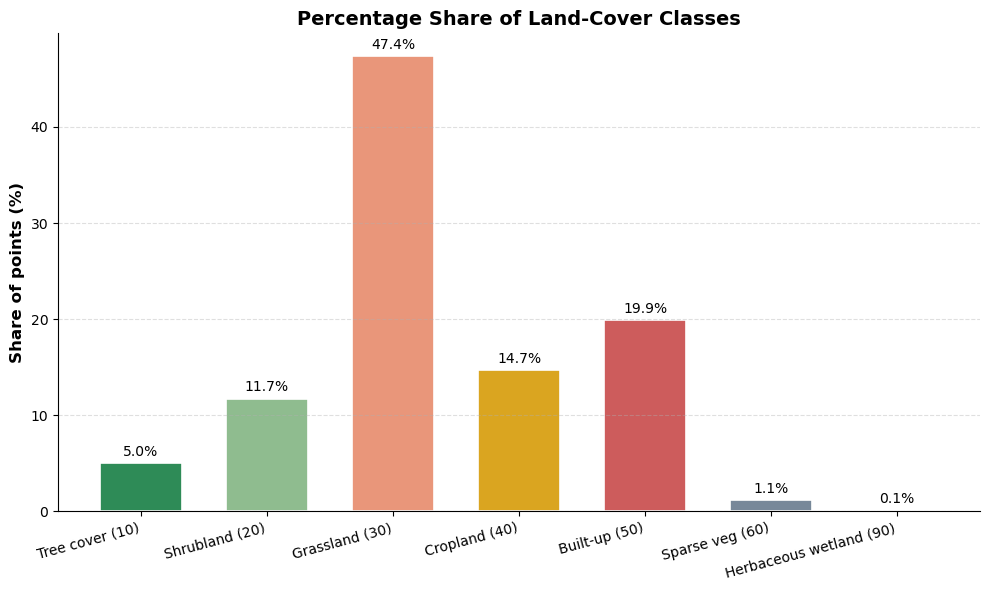

In [17]:

#1. Get the value counts sorted by index so they align with your land cover codes

land_cover_names = {
    10: "Tree cover (10)",
    20: "Shrubland (20)",
    30: "Grassland (30)",
    40: "Cropland (40)",
    50: "Built-up (50)",
    60: "Sparse veg (60)",
    90: "Herbaceous wetland (90)",
}

land_cover_share = df["land_cover"].value_counts(normalize=True).sort_index() * 100
labels = [land_cover_names[code] for code in land_cover_share.index]
values = land_cover_share.values

# 2. Define custom colors (mapped to codes so colors stay consistent even if a class is missing)
color_map = {
    10: "#2E8B57",  # Sea Green
    20: "#8FBC8F",  # Dark Sea Green
    30: "#E9967A",  # Dark Salmon
    40: "#DAA520",  # Goldenrod
    50: "#CD5C5C",  # Indian Red
    60: "#778899",  # Light Slate Gray
    90: "#4682B4",  # Steel Blue
}
bar_colors = [color_map[code] for code in land_cover_share.index]

# 3. Create the figure and plot
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    labels,
    values,
    color=bar_colors,
    edgecolor="white",
    linewidth=1.2,
    width=0.65,
)

# 4. Styling the graph
ax.set_ylabel("Share of points (%)", fontsize=12, fontweight="bold")
ax.set_title("Percentage Share of Land-Cover Classes", fontsize=14, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Add percentage labels on top of the bars (1 decimal place)
ax.bar_label(bars, padding=3, fmt="%.1f%%")

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


#### 2.4.7 Preliminary Flood Occurrence by Land-Cover Class

This analysis examines the proportion of sampled points labelled as flooded within each land-cover category.

The mean of the binary **flooded** variable is calculated for each land-cover class and multiplied by 100 to express the result as a percentage.

This helps investigate whether flood occurrence differs across land-cover categories.

The results provide an initial understanding of how land-cover characteristics may be associated with flood susceptibility in the study area.

**Note:** These percentages describe the available labelled samples. They do not establish that a particular land-cover class causes flooding.


In [10]:
#  Flood rate by land-cover class
print("Flood rate (%) by land-cover code:")
display((df.groupby("land_cover")["flooded"].mean() * 100).round(2))

Flood rate (%) by land-cover code:


land_cover
10    61.64
20    64.70
30    58.81
40    58.25
50    13.13
60    30.26
90    86.36
Name: flooded, dtype: float64

#### 2.4.8 Multivariate Analysis

In [32]:
# 1. Spearman Correlation Matrix for Terrain & Water-Distance Features
corr_matrix = df[numeric_cols].corr(method='spearman')
display("Spearman Correlation Matrix (Checking Feature Overlap):")
display(corr_matrix.round(3))

# 2. Multi-level Grouping: Land Cover & Target vs. Key Water Distances/Elevation
water_cols = [c for c in numeric_cols if any(k in c.lower() for k in ['dist', 'elevation', 'slope'])]
if 'land_cover' in df.columns and water_cols:
    multi_group = df.groupby(['land_cover', target_col])[water_cols].median()
    display("Multi-Level Median Summary (Land Cover & Target vs. Water/Elevation Metrics):")
    display(multi_group)

'Spearman Correlation Matrix (Checking Feature Overlap):'

,point_id,lon,lat,flooded,elevation,slope,local_relief_100,local_relief_500,concavity,builtup_100,builtup_500,dist_river,dist_stream,dist_drain
point_id,1.000,-0.002,-0.003,-0.006,0.003,0.001,-0.007,-0.003,-0.000,-0.007,-0.008,0.001,0.000,-0.003
lon,-0.002,1.000,0.072,0.390,-0.912,-0.381,0.031,-0.011,-0.017,-0.545,-0.599,0.258,0.240,0.949
lat,-0.003,0.072,1.000,0.103,-0.294,-0.104,-0.038,-0.030,0.044,-0.214,-0.225,-0.085,-0.112,0.237
flooded,-0.006,0.390,0.103,1.000,-0.490,-0.329,-0.178,-0.376,0.203,-0.459,-0.438,-0.137,-0.150,0.347
elevation,0.003,-0.912,-0.294,-0.490,1.000,0.339,0.039,0.148,-0.056,0.602,0.644,-0.021,0.003,-0.904
slope,0.001,-0.381,-0.104,-0.329,0.339,1.000,-0.065,-0.135,0.048,0.447,0.501,-0.379,-0.381,-0.318
local_relief_100,-0.007,0.031,-0.038,-0.178,0.039,-0.065,1.000,0.593,-0.840,-0.023,-0.081,0.165,0.166,0.007
local_relief_500,-0.003,-0.011,-0.030,-0.376,0.148,-0.135,0.593,1.000,-0.588,0.087,-0.033,0.367,0.367,-0.027
concavity,-0.000,-0.017,0.044,0.203,-0.056,0.048,-0.840,-0.588,1.000,-0.003,0.058,-0.176,-0.178,0.002
builtup_100,-0.007,-0.545,-0.214,-0.459,0.602,0.447,-0.023,0.087,-0.003,1.000,0.873,-0.036,-0.031,-0.484


'Multi-Level Median Summary (Land Cover & Target vs. Water/Elevation Metrics):'

elevation     slope   dist_river  dist_stream  \
land_cover block_id                                                    
10         259_9858  1652.622192  3.355866   663.128605   663.128605   
           259_9859  1656.647827  2.644850  1017.120719  1017.120719   
           259_9860  1654.246094  2.118070   393.863761   393.863761   
           259_9861  1649.922546  5.892786   886.263903   886.263903   
           259_9862  1636.973755  6.465338   909.057984   909.057984   
...                          ...       ...          ...          ...   
90         273_9861  1509.026123  0.697333   176.549887   176.549887   
           273_9870  1516.500000  0.428087  2259.157630  2259.157630   
           275_9869  1513.645508  0.558230  2082.449689  2082.449689   
           276_9866  1495.084167  0.336411   345.160734   345.160734   
           276_9867  1495.868042  0.339460   516.987660   516.987660   

                      dist_drain  
land_cover block_id               
10         259_9858  2706.321275  
           259_9859  2433.969874  
           259_9860  2191.470130  
           259_9861  2373.467923  
           259_9862  2612.228505  
...                          ...  
90         273_9861   915.684019  
           273_9870  6486.720897  
           275_9869  7278.572511  
           276_9866  6605.823766  
           276_9867  6741.326941  

[1820 rows x 5 columns]

#### Key Insights: Multivariate Analysis

* **Severe Multicollinearity:** `dist_river` and `dist_stream` are nearly identical
* **Spatial & Elevation Gradients:** `elevation` strongly correlates with `lon` ($r = -0.912$) and `dist_drain` ($r = -0.904$), showing that lower-lying eastern areas sit farthest from formal drainage and have higher flood susceptibility.
* **Land-Cover & Terrain Interaction:** Across land-cover classes and spatial blocks, flooded zones consistently cluster at lower elevations (around **1,495 m**) with flatter slopes (< **0.7°**), whereas higher elevations (> **1,630 m**) and steeper slopes (> **2.1°**) remain dry.

#### 2.4.9 Investigating the Water-Distance Features

In [37]:
distance_columns = ["dist_river", "dist_stream", "dist_drain"]
display(df[distance_columns].describe().T)

print(
    "Are dist_river and dist_stream identical for every row?",
    df["dist_river"].equals(df["dist_stream"])
)

print(
    "Correlation between dist_river and dist_stream:",
    df[["dist_river", "dist_stream"]].corr().iloc[0, 1].round(4)
)

,count,mean,std,min,25%,50%,75%,max
dist_river,19878.0,924.865255,981.791447,0.006882,161.863981,541.486468,1379.265397,3960.530420
dist_stream,19878.0,939.409319,981.149807,0.006882,166.184464,568.156431,1420.359440,3960.530420
dist_drain,19878.0,8124.809578,4816.577833,3.766930,3687.280848,7962.328653,12443.090507,18670.392919


Are dist_river and dist_stream identical for every row? False
Correlation between dist_river and dist_stream: 0.9918


In [38]:
# Compare water-distance features to justify feature selection in Section 3
water_cols = ['dist_river', 'dist_stream', 'dist_drain']
display(df[water_cols].corr(method='spearman').round(3))

# Check individual correlation with the target 'flooded'
display(df[water_cols + ['flooded']].corr(method='spearman')['flooded'].round(3))

,dist_river,dist_stream,dist_drain
dist_river,1.000,0.986,0.223
dist_stream,0.986,1.000,0.193
dist_drain,0.223,0.193,1.000


dist_river    -0.137
dist_stream   -0.150
dist_drain     0.347
flooded        1.000
Name: flooded, dtype: float64

In [39]:
display(df[["dist_river", "dist_stream", "dist_drain"]].describe())
print("River and stream distances are identical:", df["dist_river"].equals(df["dist_stream"]))

,dist_river,dist_stream,dist_drain
count,19878.000000,19878.000000,19878.000000
mean,924.865255,939.409319,8124.809578
std,981.791447,981.149807,4816.577833
min,0.006882,0.006882,3.766930
25%,161.863981,166.184464,3687.280848
50%,541.486468,568.156431,7962.328653
75%,1379.265397,1420.359440,12443.090507
max,3960.530420,3960.530420,18670.392919


River and stream distances are identical: False



#### 2.4.10 Examining Spatial Block Structure

The dataset is examined to understand how sampled geographic points are distributed across spatial blocks.

The analysis identifies:

- The total number of unique spatial blocks.
- The distribution of observations within these blocks.
- Whether the number of sampled points differs considerably between blocks.

Spatial blocks are important because nearby geographic observations may share similar environmental characteristics.

During model evaluation, using spatial blocks can help reduce the risk of overly optimistic results caused by training and testing on geographically close observations.

The **block_id** variable will therefore be retained as metadata for spatially informed data splitting and evaluation, rather than used as a model predictor.



In [15]:
# 4. Check spatial block structure
print("Number of unique spatial blocks:", df["block_id"].nunique())
print("Points per block summary:")
display(df["block_id"].value_counts().describe())

Number of unique spatial blocks: 525
Points per block summary:


count    525.000000
mean      37.862857
std       35.504492
min        1.000000
25%       20.000000
50%       27.000000
75%       40.000000
max      219.000000
Name: count, dtype: float64

In [34]:
# Check sample counts and flood rate (%) per spatial block
block_summary = df.groupby('block_id')['flooded'].agg(
    total_points='count',
    flooded_count='sum',
    flood_rate_pct=lambda x: round(x.mean() * 100, 2)
)
display(block_summary)

,total_points,flooded_count,flood_rate_pct
block_id,,,
259_9853,5,0,0.00
259_9854,8,0,0.00
259_9855,7,0,0.00
259_9856,10,0,0.00
259_9857,11,0,0.00
...,...,...,...
288_9867,33,26,78.79
288_9868,19,10,52.63
288_9869,55,49,89.09


**Key Insights: Spatial Clustering & Water-Distance Redundancy**

* **Spatial Clustering (**block_id**):** Across **525 spatial blocks** (1–219 points/block; median: **27**), flooding is heavily localized rather than uniform-ranging from **0.00%** in dry blocks ( 259_9853 –259_9857) to **89.09%** in high-risk zones (288_9869). 


## 3. DATA PREPARATION
The data preparation stage focuses on organising and validating the dataset before it is handed over for machine-learning development.

The main activities include:

- Confirming the selection of the water-distance feature.
- Validating the availability of required columns.
- Checking the target variable and point identifiers.
- Removing duplicate records.
- Separating predictors, target variables and metadata.
- Preparing a consistent dataset for downstream modelling.

The objective is to produce a clearly structured dataset that can be used by the modelling team while retaining the geographic information needed for spatial analysis and mapping.

### 3.1 Validate the Data Before Preparing the Shared Table

After preparing the dataset, final checks are performed to assess its structural consistency.

The checks examine:

- **Missing values:** Identifies whether any columns contain incomplete observations.
- **Duplicate records:** Confirms whether duplicate rows remain.
- **Flood labels:** Checks the distribution of the target variable after preparation.

These checks are important to ensure that the prepared dataset is suitable for the next stage of the project.

Any remaining missing values, unexpected target labels or duplicate records should be investigated before model development.

**Note:** This cell performs validation checks. It does not automatically remove missing values or correct invalid target labels.

In [21]:
required_columns = ["point_id", "lon", "lat", "flooded", "elevation", "slope",
                   "local_relief_100", "local_relief_500", "concavity", "land_cover",
                   "builtup_100", "builtup_500", "dist_river", "dist_stream",
                   "dist_drain", "block_id"]

print("Missing required columns:", [col for col in required_columns if col not in df.columns])
print("Only 0 and 1 in target:", df["flooded"].isin([0, 1]).all())
print("Point IDs are unique:", df["point_id"].is_unique)

Missing required columns: []
Only 0 and 1 in target: True
Point IDs are unique: True


### 3.2 Creating the Shared Dataset

In [22]:
prepared_df = df.drop_duplicates().copy()

# Keep only one water-distance feature and remove dist_drain.
if selected_water_feature == "dist_river":
    prepared_df = prepared_df.drop(columns=["dist_stream", "dist_drain"])
else:
    prepared_df = prepared_df.drop(columns=["dist_river", "dist_drain"])

numeric_features = ["elevation", "slope", "local_relief_100", "local_relief_500",
                    "concavity", "builtup_100", "builtup_500", selected_water_feature]
categorical_features = ["land_cover"]
feature_columns = numeric_features + categorical_features
metadata_columns = ["point_id", "lon", "lat", "block_id"]

display(prepared_df.head())
print("Prepared dataset shape:", prepared_df.shape)
print("Candidate predictors:", feature_columns)

,point_id,lon,lat,flooded,elevation,slope,local_relief_100,local_relief_500,concavity,land_cover,builtup_100,builtup_500,dist_river,block_id
0,1,37.054329,-1.299028,0,1497.815308,0.643400,0.784040,0.919611,-0.242782,40,0.009070,0.076953,343.582858,283_9856
1,2,37.051868,-1.297120,1,1491.494019,1.070903,-0.562037,-3.348700,0.486544,30,0.000000,0.098520,8.770712,283_9856
2,3,36.979077,-1.223612,1,1503.143555,0.114747,-0.132010,-1.802306,0.111572,30,0.034014,0.235663,93.445852,275_9864
3,4,37.086873,-1.232403,1,1486.456299,0.068787,-0.188992,-0.402524,0.026636,30,0.000000,0.003921,2807.757821,287_9863
4,5,37.068898,-1.188922,0,1480.674805,0.426800,-0.134649,0.193810,0.016965,30,0.000000,0.000000,1369.394675,285_9868


Prepared dataset shape: (19878, 14)
Candidate predictors: ['elevation', 'slope', 'local_relief_100', 'local_relief_500', 'concavity', 'builtup_100', 'builtup_500', 'dist_river', 'land_cover']


In [23]:
# Final check on the share data set
print("Missing values:")
display(prepared_df.isnull().sum())
print("Duplicate rows:", prepared_df.duplicated().sum())
print("Flood labels:")
display(prepared_df["flooded"].value_counts())

Missing values:


point_id            0
lon                 0
lat                 0
flooded             0
elevation           0
slope               0
local_relief_100    0
local_relief_500    0
concavity           0
land_cover          0
builtup_100         0
builtup_500         0
dist_river          0
block_id            0
dtype: int64

Duplicate rows: 0
Flood labels:


flooded
1    9971
0    9907
Name: count, dtype: int64

### 3.3 Preparing the Three Handover Files

The data preparation stage produces three important files for the next stage of the capstone project.

**1. modelling_table.csv**

Contains the prepared dataset, including the selected candidate predictors, target variable (`flooded`) and required metadata (`point_id`, `lon`, `lat`, `block_id`).

The metadata is retained for mapping, identification and spatial data splitting. It should not automatically be treated as model input.

**2. feature_list.csv**

Documents all variables and their assigned roles in the project.

It identifies which features are candidate predictors, the target variable, metadata and excluded variables.

**3. data_dictionary.csv**

Provides descriptions and planned project uses for the original dataset columns.

It helps the team understand the meaning and intended purpose of each variable.



In [24]:
# List each column and its role in the project.
feature_list = pd.DataFrame([
    ["elevation", "predictor", True],
    ["slope", "predictor", True],
    ["local_relief_100", "predictor", True],
    ["local_relief_500", "predictor", True],
    ["concavity", "predictor", True],
    ["land_cover", "predictor", True],
    ["builtup_100", "predictor", True],
    ["builtup_500", "predictor", True],
    [selected_water_feature, "predictor", True],
    ["flooded", "target", False],
    ["point_id", "metadata", False],
    ["lon", "metadata", False],
    ["lat", "metadata", False],
    ["block_id", "metadata", False],
    ["dist_drain", "excluded", False],
    ["dist_stream" if selected_water_feature == "dist_river" else "dist_river", "excluded", False]
], columns=["feature_name", "role", "included_in_modelling_inputs"])

feature_list["data_type"] = feature_list["feature_name"].map(df.dtypes.astype(str))
display(feature_list)

prepared_df.to_csv("modelling_table.csv", index=False)
feature_list.to_csv("feature_list.csv", index=False)
data_dictionary.to_csv("data_dictionary.csv", index=False)
print("The three project files have been saved.")

,feature_name,role,included_in_modelling_inputs,data_type
0,elevation,predictor,True,float64
1,slope,predictor,True,float64
2,local_relief_100,predictor,True,float64
3,local_relief_500,predictor,True,float64
4,concavity,predictor,True,float64
5,land_cover,predictor,True,int64
6,builtup_100,predictor,True,float64
7,builtup_500,predictor,True,float64
8,dist_river,predictor,True,float64
9,flooded,target,False,int64


The three project files have been saved.
